# Exercice 1 — EnergyTransformer

Objectif : prédire la **puissance active moyenne de l'heure suivante**, en kW,
à partir des **24 heures précédentes**.

Les mesures viennent du fichier UCI *Individual Household Electric Power Consumption*,
fourni dans l'archive du projet. On utilise seulement `Global_active_power`.
Les points d'interrogation sont des valeurs manquantes.

Chaque prédiction de test est faite à partir des **vraies** heures déjà observées.
On ne réinjecte pas les prédictions du modèle dans la fenêtre suivante.
        

In [1]:
import sys
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training import count_parameters, get_device, set_seed

set_seed(42)
device = get_device()
print("Dossier du projet :", ROOT)
print("Périphérique :", device)

Dossier du projet : /Users/hmid/Downloads/Deep-Learning-Transformers
Périphérique : mps


## 1. Préparation, sans fuite

1. Lire le fichier avec `sep=';'` et `na_values=['?']`.
2. Construire l'horodatage `Date + Time`.
3. Moyenner par heure et écarter les heures de moins de 45 mesures valides.
4. Couper la série dans l'ordre : 70 % train, 15 % validation, 15 % test.
5. Calculer la moyenne et l'écart-type **uniquement** sur le train.
6. Former des fenêtres de 24 heures et supprimer celles qui contiennent un NaN.

Le lot d'une fenêtre dépend de l'indice de sa cible. Les entrées sont toujours
les 24 heures d'avant. Une fenêtre de validation peut donc commencer à la fin
du train : ce sont des observations passées, pas la cible de test.
        

In [2]:
from torch.utils.data import DataLoader, TensorDataset

from src.data import load_hourly_power, window_split

serie = load_hourly_power()
prepare = window_split(serie)
print("Heures de la série, y compris les trous :", prepare["n"])
print("Heures numériques :", int(serie.notna().sum()))
print("Début :", serie.index[0], "| fin :", serie.index[-1])
print("Fin du train :", prepare["fin_train"], "| fin de la validation :", prepare["fin_val"])
print(f"Moyenne train : {prepare['mean']:.4f} kW | écart-type train : {prepare['std']:.4f} kW")
print("Fenêtres train / val / test :",
      len(prepare["X_train"]), len(prepare["X_val"]), len(prepare["X_test"]))
print("Forme d'une entrée :", tuple(prepare["X_train"].shape[1:]))
print("Exemple normalisé, 24 heures :")
print(np.array2string(prepare["X_train"][0, :, 0].numpy(), precision=3))
        

Heures de la série, y compris les trous : 34589
Heures numériques : 34151
Début : 2006-12-16 17:00:00 | fin : 2010-11-26 21:00:00
Fin du train : 24212 | fin de la validation : 29400
Moyenne train : 1.0865 kW | écart-type train : 0.9287 kW
Fenêtres train / val / test : 23805 5054 4932
Forme d'une entrée : (24, 1)
Exemple normalisé, 24 heures :
[2.741 2.491 2.35  2.121 1.199 1.05  0.857 2.437 0.539 0.62  1.216 0.98
 0.233 0.574 0.866 1.575 2.737 1.491 0.893 0.618 1.083 2.045 2.411 2.498]


## 2. Le modèle

`EnergyTransformer` suit la consigne :

- `Linear(1, 32)`, puis des positions apprises ;
- deux `TransformerEncoderLayer` ;
- `d_model=32`, `nhead=4`, `dim_feedforward=128`, `dropout=0.1`, `batch_first=True` ;
- `Linear(32, 1)` appliqué à la dernière heure.

L'optimiseur est Adam avec un pas de 0,001. La perte est la MSE sur les valeurs
normalisées. On fait au plus 20 époques, par lots de 64, et on recharge l'époque
dont la perte de validation est la plus basse.
        

In [3]:
from src.models import EnergyTransformer
from src.training import train_with_validation

set_seed(42)
generateur = torch.Generator().manual_seed(42)
train_loader = DataLoader(
    TensorDataset(prepare["X_train"], prepare["y_train"]),
    batch_size=64,
    shuffle=True,
    generator=generateur,
)
val_loader = DataLoader(TensorDataset(prepare["X_val"], prepare["y_val"]), batch_size=64)
modele = EnergyTransformer()
print("Paramètres :", count_parameters(modele))
historique = train_with_validation(
    modele,
    train_loader,
    val_loader,
    epochs=20,
    lr=0.001,
    device=device,
    checkpoint_path=ROOT / "outputs" / "checkpoints" / "energy_transformer.pt",
)
        

Paramètres : 26273


Epoch  1 | train 0.465057 | val 0.402721  <- meilleur


Epoch  2 | train 0.426896 | val 0.390532  <- meilleur


Epoch  3 | train 0.423642 | val 0.395922


Epoch  4 | train 0.418119 | val 0.384941  <- meilleur


Epoch  5 | train 0.414180 | val 0.394962


... (11 outputs left out)

Epoch 17 | train 0.396692 | val 0.374142  <- meilleur


Epoch 18 | train 0.395845 | val 0.390902


Epoch 19 | train 0.394490 | val 0.380657


Epoch 20 | train 0.391699 | val 0.384315
Meilleur modèle restauré : époque 17, MSE validation 0.374142
Checkpoint enregistré : /Users/hmid/Downloads/Deep-Learning-Transformers/outputs/checkpoints/energy_transformer.pt


## 3. Erreurs en kilowatts

On dénormalise avec la moyenne et l'écart-type **du train** :

$$
\text{kW} = z \times \sigma_{train} + \mu_{train}
$$

La persistance répète la dernière heure de la fenêtre, donc l'heure `t-1`.
La référence journalière répète la première heure de la fenêtre, donc l'heure `t-24`.
        

                     mse    mae   rmse
EnergyTransformer 0.2365 0.3430 0.4863
Persistance       0.3462 0.3892 0.5884
Veille (t-24)     0.5835 0.5133 0.7639


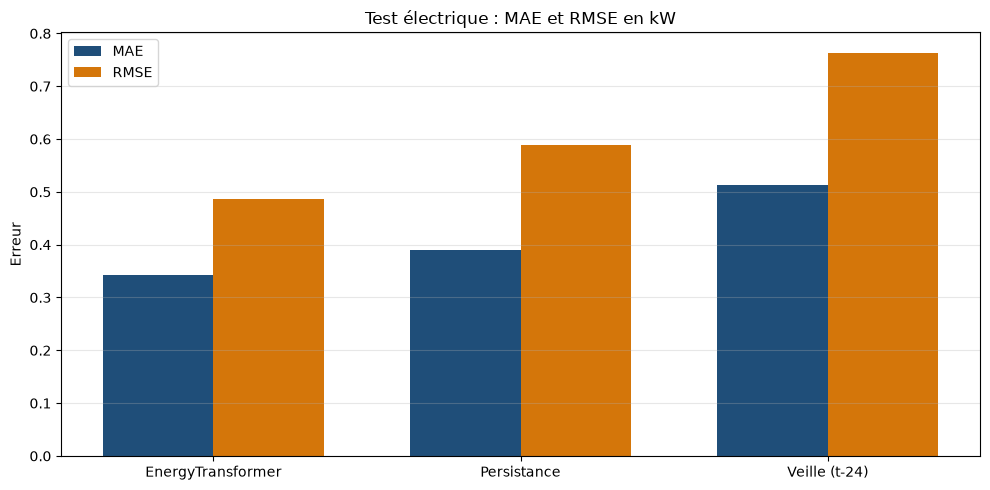

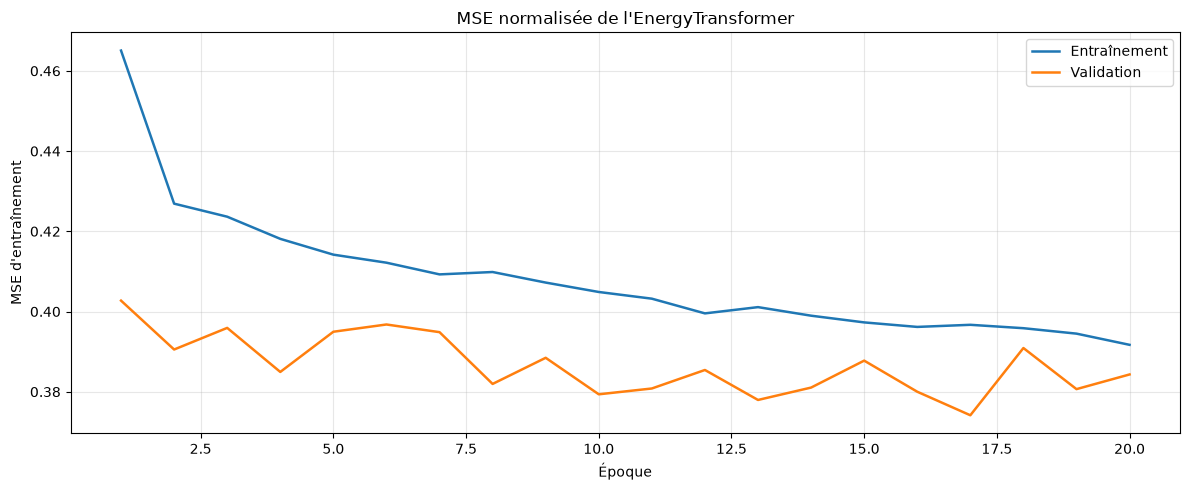

In [4]:
from src.evaluation import (
    baseline_predictions,
    consecutive_run,
    denormalize,
    longest_consecutive,
    plot_loss_curves,
    plot_metric_bars,
    plot_week,
    regression_scores,
    save_figure,
    save_json,
)
from src.training import predict

prediction_norm = predict(modele, prepare["X_test"], device=device)
reel_kw = denormalize(prepare["y_test"], prepare["mean"], prepare["std"])
pred_kw = denormalize(prediction_norm, prepare["mean"], prepare["std"])
bases = baseline_predictions(prepare["X_test"], prepare["mean"], prepare["std"])

scores = {
    "EnergyTransformer": regression_scores(reel_kw, pred_kw),
    "Persistance": regression_scores(reel_kw, bases["persistance"]),
    "Veille (t-24)": regression_scores(reel_kw, bases["veille"]),
}
tableau = pd.DataFrame(scores).T
print(tableau.to_string(float_format=lambda valeur: f"{valeur:.4f}"))

figure = plot_metric_bars(scores, "Test électrique : MAE et RMSE en kW")
save_figure(figure, ROOT / "outputs" / "figures" / "03_energy_barres.png")
plt.show()

figure = plot_loss_curves(
    {
        "Entraînement": [ligne["train_loss"] for ligne in historique],
        "Validation": [ligne["val_loss"] for ligne in historique],
    },
    "MSE normalisée de l'EnergyTransformer",
)
save_figure(figure, ROOT / "outputs" / "figures" / "03_energy_pertes.png")
plt.show()
        

Plage de sept jours consécutifs trouvée.
Du 2010-04-24 17:00:00 au 2010-05-01 16:00:00


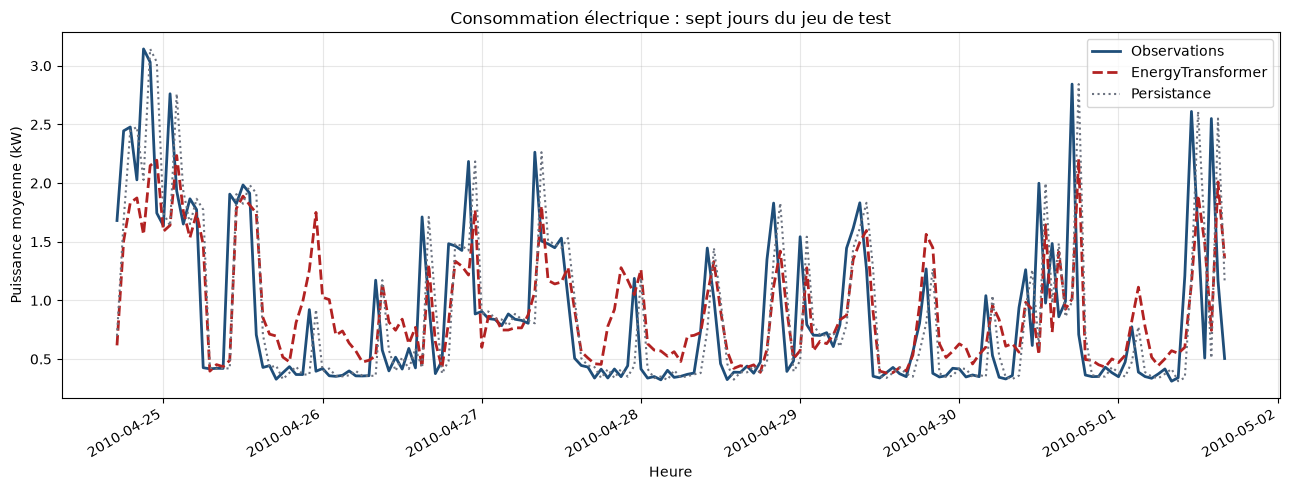

EnergyTransformer: MAE 0.3430 kW | RMSE 0.4863 kW
Persistance: MAE 0.3892 kW | RMSE 0.5884 kW
Veille (t-24): MAE 0.5133 kW | RMSE 0.7639 kW


In [5]:
positions = prepare["positions_test"]
debut = consecutive_run(positions, 168)
if debut is None:
    debut, longueur = longest_consecutive(positions)
    print(f"Aucune plage de 168 heures. Plus longue plage continue : {longueur} heures.")
else:
    longueur = 168
    print("Plage de sept jours consécutifs trouvée.")

instants = prepare["index"][positions[debut:debut + longueur]]
print("Du", instants[0], "au", instants[-1])
figure = plot_week(
    instants,
    reel_kw[debut:debut + longueur],
    pred_kw[debut:debut + longueur],
    bases["persistance"][debut:debut + longueur],
)
save_figure(figure, ROOT / "outputs" / "figures" / "03_energy_sept_jours.png")
plt.show()

save_json(ROOT / "outputs" / "metrics" / "03_energy.json", {
    "device": str(device),
    "mean_train_kw": prepare["mean"],
    "std_train_kw": prepare["std"],
    "n_train": int(len(prepare["X_train"])),
    "n_val": int(len(prepare["X_val"])),
    "n_test": int(len(prepare["X_test"])),
    "meilleure_epoque": int(min(historique, key=lambda ligne: ligne["val_loss"])["epoch"]),
    "scores_kw": scores,
    "fenetre_graphique": {
        "debut": str(instants[0]),
        "fin": str(instants[-1]),
        "heures": int(longueur),
    },
})

for nom, mesure in scores.items():
    print(
        f"{nom}: MAE {mesure['mae']:.4f} kW | RMSE {mesure['rmse']:.4f} kW"
    )
        

## 4. Questions de réflexion

Les réponses distinguent ce qui a été **mesuré** dans les cellules précédentes
et ce qui reste une **hypothèse**. Les chiffres exacts sont ceux du tableau,
pas une valeur apprise par cœur avant l'exécution.

### Le Transformer améliore-t-il les deux références ?

Réponse mesurée : comparer la MAE et la RMSE du modèle à celles de la persistance
et de la veille. Une amélioration n'existe que si les deux erreurs du modèle
sont plus basses. Si la persistance reste meilleure, il faut le dire :
l'électricité d'une heure ressemble beaucoup à celle de l'heure précédente,
et 20 époques d'un petit encodeur ne garantissent pas de battre cette copie.

### Une fenêtre de 168 heures capturerait-elle mieux la semaine ?

Hypothèse non testée. Le graphique de sept jours montre un rythme jour / nuit,
et le corpus du cours rappelle qu'un même jour de la semaine précédente est hors
de portée d'une fenêtre de 24 heures. Une fenêtre de 168 heures pourrait voir
ce cycle. Elle n'a pas été entraînée ici. Son coût d'attention grandirait,
et il faudrait refaire le découpage sans fuite avant de conclure.

### À quoi serviraient l'heure et le jour ?

Hypothèse non testée. L'heure du jour et le jour de la semaine sont des indices
calendaires que la puissance seule ne nomme pas explicitement. Les positions
apprises distinguent « il y a 1 heure » de « il y a 23 heures », mais elles ne
disent pas « c'est un dimanche ». Ajouter ces variables pourrait aider les
horaires réguliers. Ce notebook ne contient pas cette expérience.

### Pourquoi normaliser seulement avec le train ?

La moyenne et l'écart-type décrivent le jeu qui sert à apprendre. Si on les
calcule avec le test, une information du futur entre dans le prétraitement :
c'est une fuite. Au moment d'une vraie prévision, le futur n'est pas connu.
Le test de `tests/test_data.py` vérifie qu'en changeant la fin de la série,
ces deux statistiques ne bougent pas. Le retour en kilowatts utilise les mêmes
statistiques de train.

### Comment prédire des kWh plutôt que des kW ?

`Global_active_power` est une puissance en kilowatts. La moyenne des minutes
d'une heure complète est numériquement égale à l'énergie de cette heure en kWh,
parce qu'une heure multipliée par la puissance moyenne redonne des kilowattheures.
Si les 60 minutes sont présentes, `somme(puissance) / 60` et la moyenne coïncident.
Comme on exige seulement 45 mesures, cette égalité n'est plus exacte pour les
heures incomplètes : l'énergie devrait alors sommer les minutes réellement
observées, en comptant chaque minute comme un soixantième d'heure, sans remplacer
les trous par la moyenne. Cette adaptation n'a pas été réentraînée.
        

## Résultats mesurés de cette exécution

Série horaire du 16 décembre 2006 17 h au 26 novembre 2010 21 h : 34 589 heures, dont 34 151 assez complètes. Fenêtres : 23 805 train, 5 054 validation, 4 932 test. Moyenne d'entraînement 1,0865 kW, écart-type 0,9287 kW. Meilleure époque de validation : 17.

| Méthode | MAE (kW) | RMSE (kW) |
|---|---:|---:|
| EnergyTransformer | 0,3430 | 0,4863 |
| Persistance | 0,3892 | 0,5884 |
| Veille, 24 h avant | 0,5133 | 0,7639 |

Le modèle améliore les deux références sur ce test. Le graphique du 24 avril 2010 17 h au 1er mai 2010 16 h montre aussi qu'il lisse certaines pointes. Les questions sur 168 heures, sur l'heure du jour et sur les kWh restent des hypothèses : elles n'ont pas été réentraînées.